In this tutorial we will apply PCA and t-SNE in a real dataset. We will compare their outcomes with LDA learned before.



title: "Dimensionality reduction in a real dataset"
output: html_document

In [3]:
library(dplyr)
library(factoextra)
library(MASS)
library(ROCR)
library(Rtsne)

## Breast cancer dataset

The Breast Cancer Wisconsin Diagnostic Data Set is a widely used dataset for breast cancer detection and classification. It contains 569 samples of breast tissue, each described by 30 numerical features derived from fine needle aspirates of breast masses (a type of biopsy performed using a small needle to obtain samples of tissue and fluid from solid or cystic breast lesions). These features include mean, standard error, and worst (maximum) values for various cell characteristics like radius, texture, smoothness, compactness, concavity, symmetry, and fractal dimension.

Each sample is labeled as either malignant (cancerous) or benign (non-cancerous). The dataset is balanced, making it suitable for binary classification tasks. It is often used in machine learning and statistical modeling for diagnostic purposes. The dataset can be also downloaded here https://www.kaggle.com/uciml/breast-cancer-wisconsin-data.


In [ ]:
data <- read.csv("breast_cancer.csv")
data <- data %>% 
  dplyr::select(-id, -X) # remove unnecessary columns

# Explore the data
data_numeric <- data %>% 
  dplyr::select(-diagnosis)

glimpse(data_numeric)



Rows: 569
Columns: 30
$ radius_mean             <dbl> 17.990, 20.570, 19.690, 11.420, 20.290, 12.450~
$ texture_mean            <dbl> 10.38, 17.77, 21.25, 20.38, 14.34, 15.70, 19.9~
$ perimeter_mean          <dbl> 122.80, 132.90, 130.00, 77.58, 135.10, 82.57, ~
$ area_mean               <dbl> 1001.0, 1326.0, 1203.0, 386.1, 1297.0, 477.1, ~
$ smoothness_mean         <dbl> 0.11840, 0.08474, 0.10960, 0.14250, 0.10030, 0~
$ compactness_mean        <dbl> 0.27760, 0.07864, 0.15990, 0.28390, 0.13280, 0~
$ concavity_mean          <dbl> 0.30010, 0.08690, 0.19740, 0.24140, 0.19800, 0~
$ concave.points_mean     <dbl> 0.14710, 0.07017, 0.12790, 0.10520, 0.10430, 0~
$ symmetry_mean           <dbl> 0.2419, 0.1812, 0.2069, 0.2597, 0.1809, 0.2087~
$ fractal_dimension_mean  <dbl> 0.07871, 0.05667, 0.05999, 0.09744, 0.05883, 0~
$ radius_se               <dbl> 1.0950, 0.5435, 0.7456, 0.4956, 0.7572, 0.3345~
$ texture_se              <dbl> 0.9053, 0.7339, 0.7869, 1.1560, 0.7813, 0.8902~
$ perimeter_se    

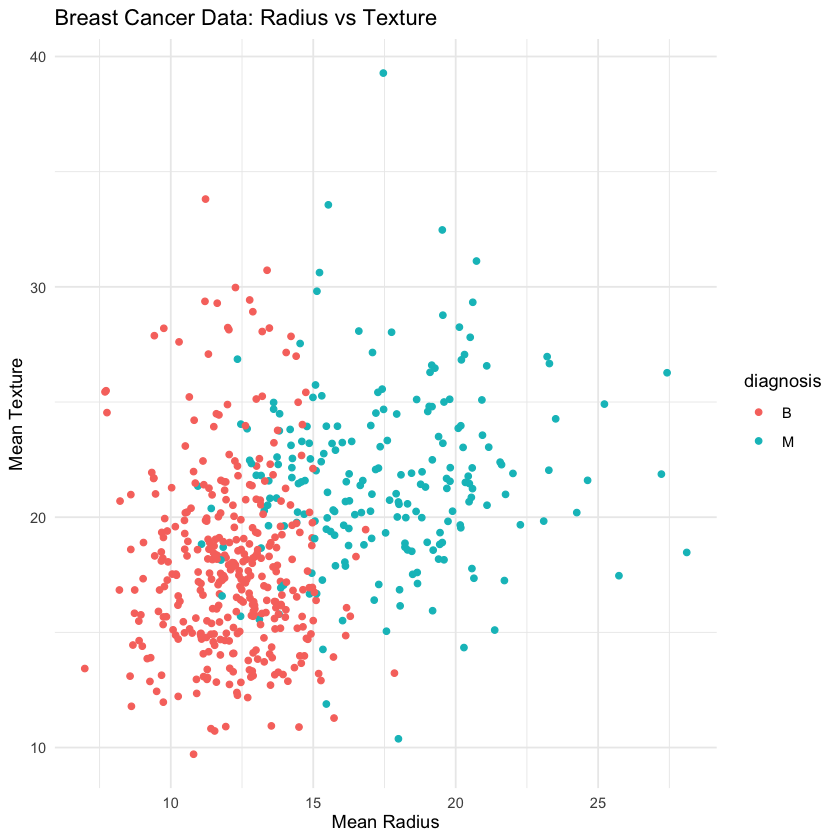

In [11]:
ggplot(data, aes(x = radius_mean, y = texture_mean, color = diagnosis)) +
  geom_point() +
  labs(title = "Breast Cancer Data: Radius vs Texture",
       x = "Mean Radius",
       y = "Mean Texture") +
  theme_minimal()

Ignoring unknown labels:
* linetype : "Diagnosis"
* shape : "Diagnosis"


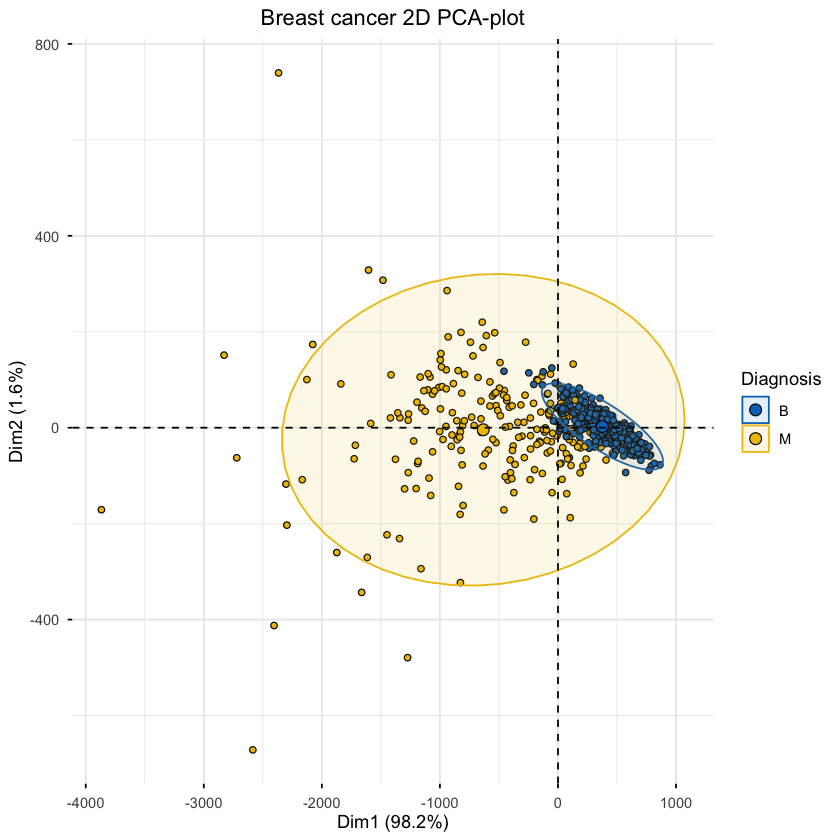

In [5]:
# Perform PCA
data_pca <- prcomp(data_numeric)

# Plot the PCA output. Is it a good projection given how many features we have?
lbs <- data$diagnosis
fviz_pca_ind(data_pca, geom.ind = "point", pointshape = 21, 
             fill.ind = lbs,
             palette = "jco", 
             addEllipses = TRUE,
             legend.title = "Diagnosis") +
  ggtitle("Breast cancer 2D PCA-plot") +
  theme(plot.title = element_text(hjust = 0.5))

,PC1,PC2,PC3,PC4,PC5,PC6
Standard deviation,666.17010,85.49912,26.52987,7.392478,6.315854,1.733375
Proportion of Variance,0.98204,0.01618,0.00156,0.000120,0.000090,0.000010
Cumulative Proportion,0.98204,0.99822,0.99978,0.999900,0.999990,0.999990


area_worst       area_mean         area_se perimeter_worst  perimeter_mean 
    0.852063392     0.516826469     0.055727167     0.049457645     0.035076330 
   radius_worst 
    0.007154733

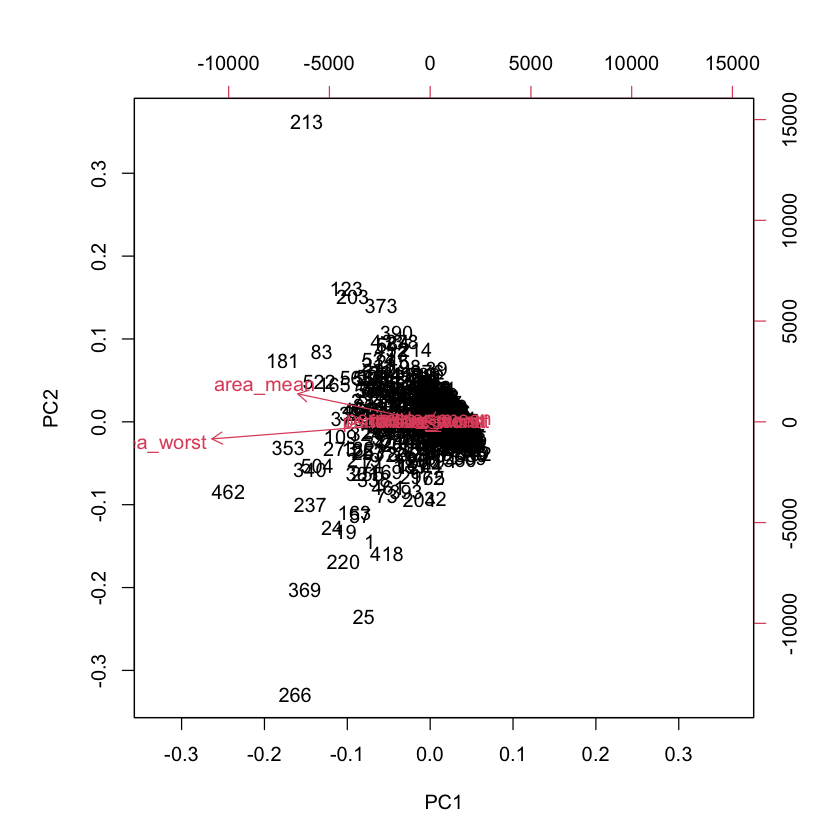

In [6]:
# Test your understanding of PCA
# How many components do we need to sufficiently capture data?
pca_summary<-summary(data_pca)
pca_summary$importance[,1:6]

# What is the primary composition of first two principal components
loadings <- abs(data_pca$rotation[, 1:2])  # Loadings for PC1 and PC2
top_vars <- names(sort(rowSums(loadings), decreasing = TRUE)[1:8])
data_pca_subset <- data_pca
data_pca_subset$rotation <- data_pca_subset$rotation[top_vars, ]
biplot(data_pca_subset)

# If the projection is too dense, can you obtain the information other ways?
data_pca$rotation[,"PC1"] %>% abs() %>% sort(decreasing = T) %>% head()

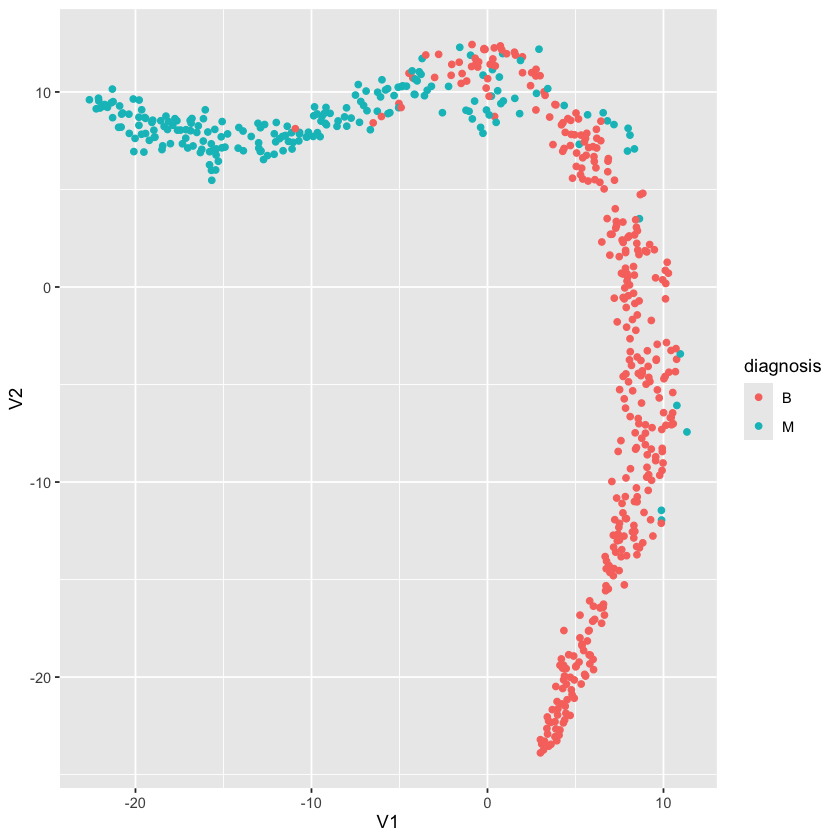

In [7]:
# Reduce the dimensions using t-SNE

tsne_res <- Rtsne::Rtsne(data_numeric, perplexity=50)

tsne_res$Y %>% 
  as.data.frame() %>%
  mutate(diagnosis = data$diagnosis) %>% 
  ggplot(aes(x=V1, y=V2, col=diagnosis)) + 
  geom_point()

,LD1
radius_mean,-1.075583600
texture_mean,0.022450225
perimeter_mean,0.117251982
area_mean,0.001569797
smoothness_mean,0.418282533
compactness_mean,-20.852775912
concavity_mean,6.904756198
concave.points_mean,10.578586272
symmetry_mean,0.507284238
fractal_dimension_mean,0.164280222


[1] "Confusion matrix:"


   labels
      B   M
  B 355  18
  M   2 194

[1] "LDA train accuracy: 0.964850615114236"
[1] "LDA train AUROC: 0.996525025104381"


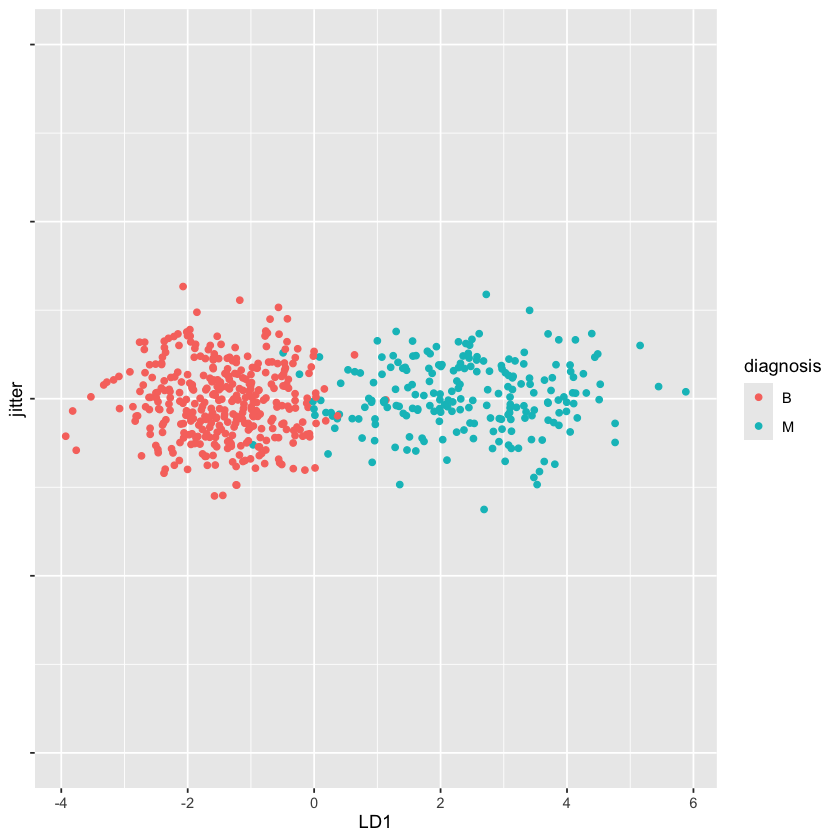

In [8]:
# LDA works with labels
labels <- data$diagnosis %>% as.factor()

# Load the LDA() and other supporting function from the 3rd assignment into the environment.
lda_model <- lda(data_numeric, labels)

# Now you can compare LDA and PCA dimensionality reduction:
lda_model$scaling

# Initial test of LDA predictive accuracy, no CV
lda_values <- predict(lda_model)

lda_plotData <- as.data.frame(lda_values$x) %>% 
  mutate(diagnosis=labels,
         jitter=rnorm(nrow(data)))

lda_plotData %>% 
  ggplot(aes(x=LD1, y=jitter, col=diagnosis)) + 
  geom_point() +
  scale_y_continuous(limits=c(-10, 10),labels = NULL)

print("Confusion matrix:")
table(lda_values$class,labels)
print(paste("LDA train accuracy:", sum(diag(table(lda_values$class,labels)))/length(labels)))
print(paste("LDA train AUROC:", performance(prediction(lda_values$posterior[,2],labels), measure = "auc")@y.values[[1]][1]))

# Independent work

1. Briefly summarize the main analytical conclusions about the dataset.
2. What are the disadvantages of using all features, for example, in a classification task or visualization? How do we select the "right features"?
3. Investigate the influence of the settings in the individual dimension reduction methods on their outcomes. Specifically, focus on scaling in PCA and LDA (no scaling was performed above) and perplexity in t-SNE.
4. Complete the code below and compare the classification accuracy achieved with the three approaches. Explain the differences. Study the role of scaling.


While running the cv we are getting an error glm.fit algorithm doesn't converge, which means that there is a problem with our data. This can be fixed by scaling our features 

In [18]:
# split the data
train.idx <- sample(1:nrow(data),size = nrow(data) * 0.7)

# run the logistic model with the given dataset
# use the train/test split given by train.idx
data_scaled <- as.data.frame(scale(data_numeric))

logReg<-function(data_scaled,labels,train.idx){
  # train the model
  logistic_data <- data.frame(data,labels)
  logistic_model <- glm(labels ~ ., data = logistic_data[train.idx, ], family = binomial)
  logistic_predictions <- predict(logistic_model, newdata = logistic_data[-train.idx, ], type = "response")
  # report test accuracy and AUROC
  return(c(sum(diag(table(logistic_predictions>0.5,labels[-train.idx])))/length(labels[-train.idx]),
           performance(prediction(logistic_predictions,labels[-train.idx]), measure = "auc")@y.values[[1]][1]))
}

# run logistic regression on all features as a benchmark
paste("Logistic regression with all features (accuracy and AUROC for test data):",paste(logReg(data_numeric,labels,train.idx),collapse=","))


Warning message:
"glm.fit: algorithm did not converge"


[1] "Logistic regression with all features (accuracy and AUROC for test data): 1,1"